In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.linear_model import RidgeCV, LassoCV,ElasticNetCV
from sklearn.model_selection import RepeatedKFold
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# Configuração visual para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Carregamento e Inspeção Inicial
df = pd.read_csv('dataset_grupo_01.csv')

print("--- Dimensões do Dataset ---")
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")

print("\n--- Primeiras Instâncias ---")
display(df.head())

print("\n--- Tipos de Dados e Valores em Falta ---")
df.info()

print("\n--- Verificação de Valores Nulos por Coluna ---")
print(df.isnull().sum()[df.isnull().sum() > 0])

--- Dimensões do Dataset ---
Linhas: 2000 | Colunas: 35

--- Primeiras Instâncias ---


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Mature,Male,Obese,Former,63,0.701149,34.70,5.415916,235.000000,9.100000,...,88.000000,125.000000,Primary,Unemployed,121.000000,9.42,1.288610,94.000000,70.0,N
1,Mature,Male,Obese,Never,59,0.655172,30.07,6.100000,225.628141,6.816071,...,64.268197,130.545353,Primary,Employed,133.613102,9.42,1.113728,153.000000,130.0,N
2,Middle,Female,Obese,Never,44,0.482758,31.70,6.804854,266.000000,9.800000,...,46.000000,158.000000,Primary,Employed,106.000000,9.42,1.193225,134.453901,92.0,DI_HY
3,Middle,Female,Overweight,Former,42,0.459770,28.50,5.405910,252.000000,5.000000,...,88.000000,90.000000,Secondary,Retired,96.000000,9.42,1.169763,101.000000,117.0,N
4,Mature,Female,Normal,Never,61,0.678161,23.38,6.000000,231.381443,6.968389,...,64.248021,130.816183,Tertiary,Retired,133.725594,9.42,1.378711,171.000000,145.0,N



--- Tipos de Dados e Valores em Falta ---
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   str    
 1   gender                2000 non-null   str    
 2   bmi_level             2000 non-null   str    
 3   smoking               2000 non-null   str    
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   str    
 12  family_history        2000 non-null   str    
 13  stress_level          2000 non-null   str    
 14  low_hdl_cholesterol   2000 non-null   st

--- Estatísticas Descritivas (Variáveis Numéricas) ---


,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,blood_pressure,crp_level,homocysteine_level,...,alcohol_intake,salt_intake,heart_rate,hdl,ldl,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00,2000.000000,2000.000000,2000.000000
mean,49.817500,0.549626,27.360674,5.823790,223.647108,6.941153,178.811071,149.687674,7.483729,12.453406,...,15.193352,8.544985,74.730287,64.426663,129.432779,134.426598,9.42,1.253070,129.432779,133.718000
std,21.924086,0.252001,6.883579,0.928032,34.915456,1.415719,66.089529,3.626313,0.882769,0.844962,...,6.873160,2.918042,11.537448,15.704977,27.339069,20.678479,0.00,0.148442,27.339069,36.750902
min,2.000000,0.000000,13.750000,3.500000,150.000000,4.000000,50.000000,121.000000,0.467803,5.309536,...,0.000000,2.000000,50.000000,30.000000,70.000000,90.000000,9.42,0.773790,70.000000,70.000000
25%,31.000000,0.333333,22.200000,5.374129,201.000000,6.200000,131.750000,148.625000,7.294863,12.287763,...,12.275000,7.375000,70.000000,56.000000,117.000000,126.000000,9.42,1.151398,117.000000,100.000000
50%,50.000000,0.551724,27.320000,5.494662,224.842938,6.982952,179.000000,149.587719,7.458483,12.504625,...,15.027543,8.477600,74.487247,64.650655,129.983051,134.176874,9.42,1.255863,129.983051,139.000000
75%,68.000000,0.758620,32.402500,6.750000,242.000000,7.700000,243.026316,150.654054,7.767442,12.681166,...,18.700000,10.000000,79.000000,71.000000,141.000000,144.000000,9.42,1.351915,141.000000,160.000000
max,89.000000,1.000000,68.530000,9.000000,299.000000,10.000000,388.000000,176.000000,14.922016,19.959139,...,30.000000,15.000000,99.000000,99.000000,189.000000,179.000000,9.42,1.714795,189.000000,280.000000



--- Estatísticas Descritivas (Variáveis Categóricas) ---


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\93773633.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['O']))


,age_level,gender,bmi_level,smoking,physical_activity,family_history,stress_level,low_hdl_cholesterol,high_ldl_cholesterol,sugar_consumption,education_level,employment_status,target_class
count,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
unique,4,2,4,3,3,2,3,2,2,3,3,3,3
top,Mature,Female,Obese,Never,High,No,High,No,Yes,Low,Tertiary,Retired,N
freq,620,1055,690,925,879,1132,763,1626,1013,887,740,688,863


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\93773633.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='target_class', ax=axes[0], palette='Set2')


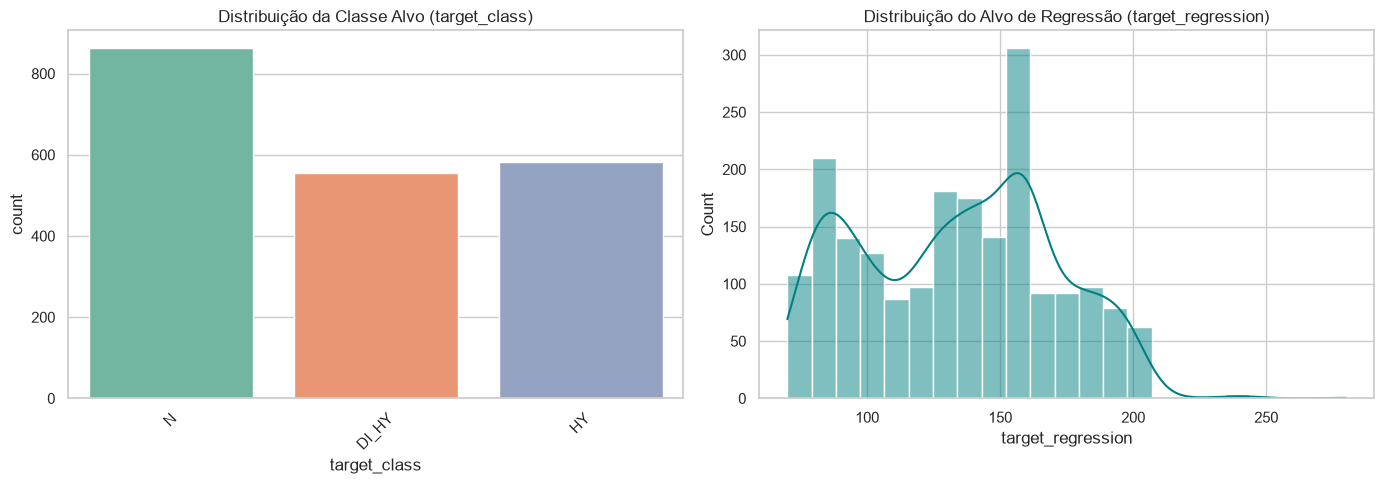

In [3]:
# Estatísticas descritivas para variáveis numéricas
print("--- Estatísticas Descritivas (Variáveis Numéricas) ---")
display(df.describe())

# Estatísticas descritivas para variáveis categóricas
print("\n--- Estatísticas Descritivas (Variáveis Categóricas) ---")
display(df.describe(include=['O']))

# Visualização da Distribuição das Variáveis Alvo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# target_class (Categórica)
sns.countplot(data=df, x='target_class', ax=axes[0], palette='Set2')
axes[0].set_title('Distribuição da Classe Alvo (target_class)')
axes[0].tick_params(axis='x', rotation=45)

# target_regression (Contínua)
sns.histplot(data=df, x='target_regression', kde=True, ax=axes[1], color='teal')
axes[1].set_title('Distribuição do Alvo de Regressão (target_regression)')

plt.tight_layout()
plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['O']).columns


--- A gerar histogramas para variáveis numéricas ---


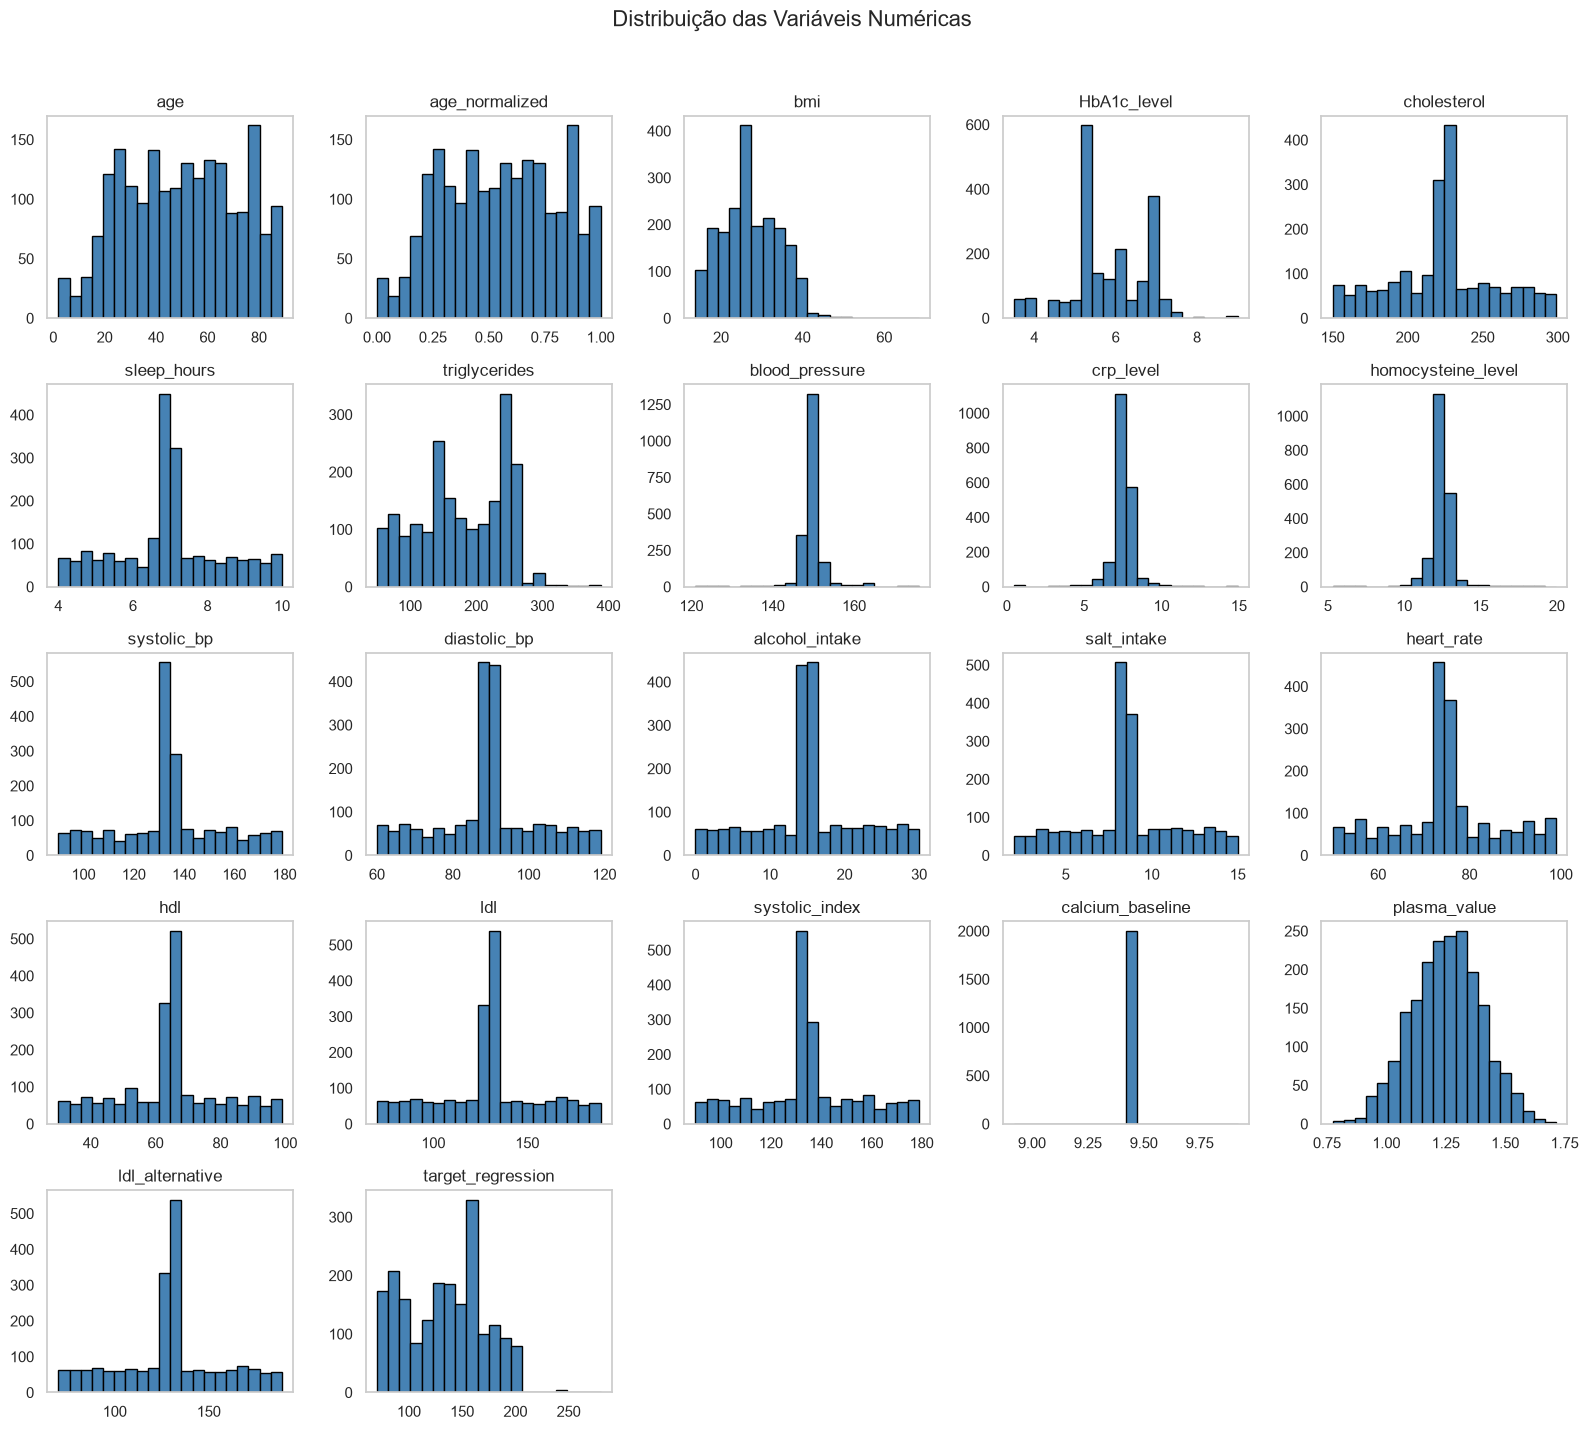

--- A gerar gráficos para variáveis categóricas ---


C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


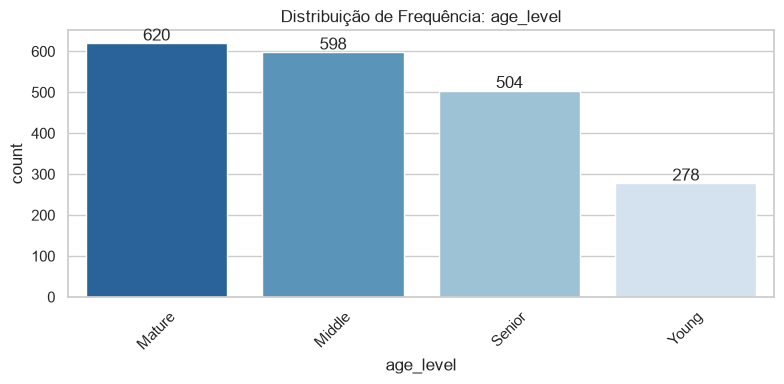

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


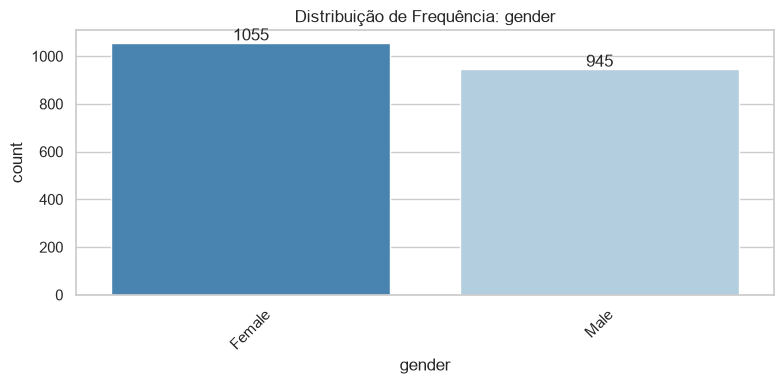

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


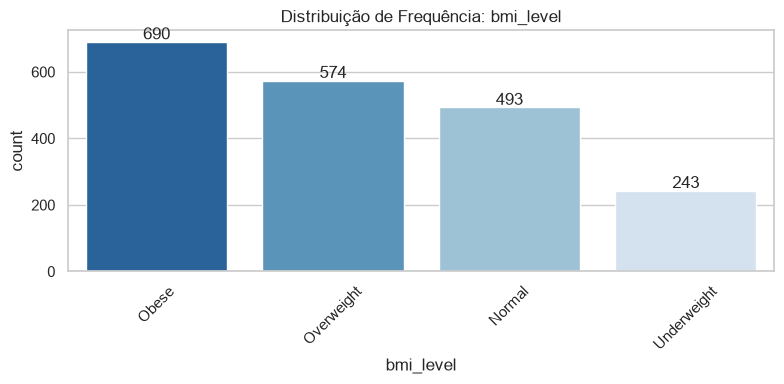

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


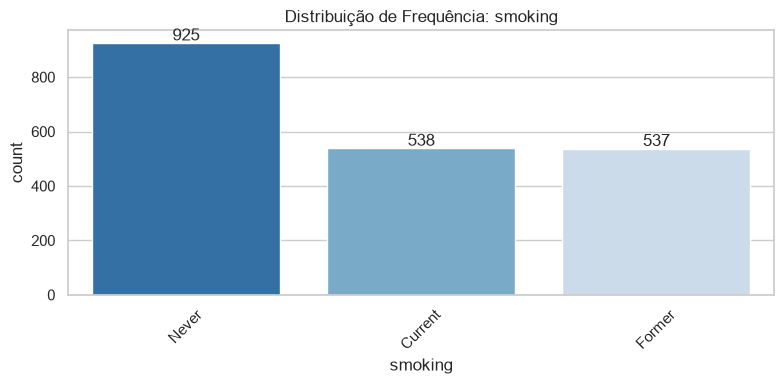

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


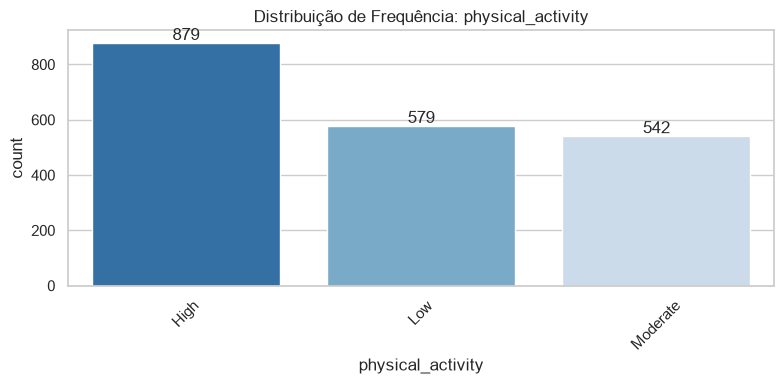

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


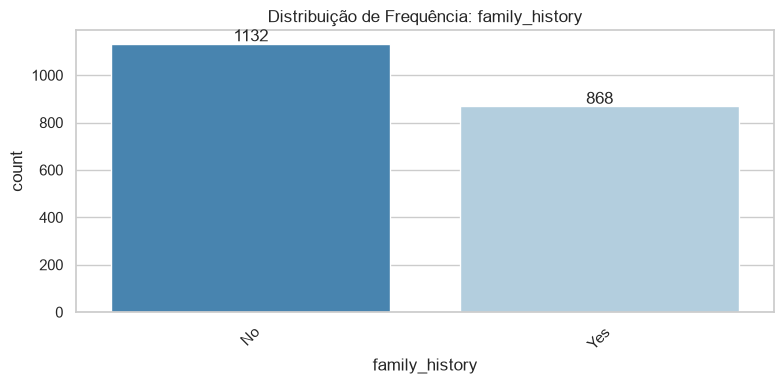

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


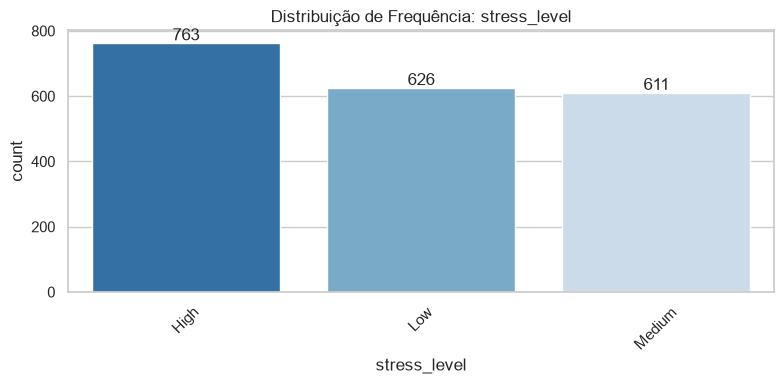

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


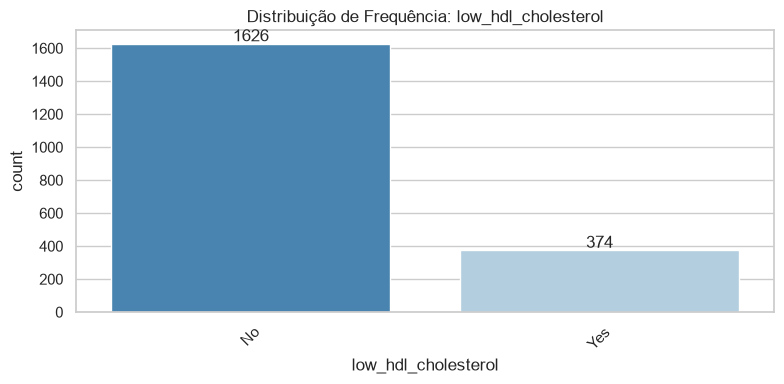

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


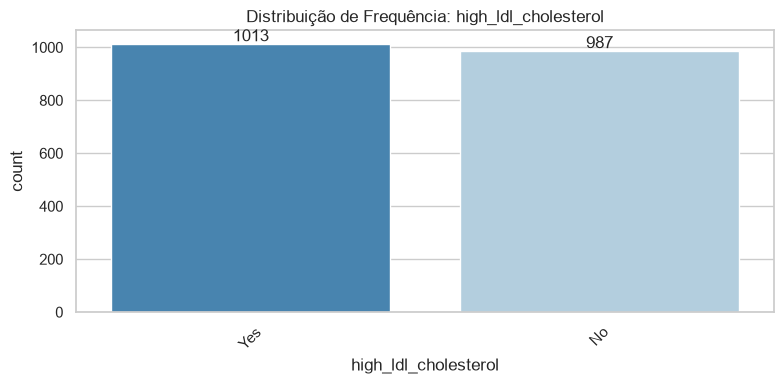

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


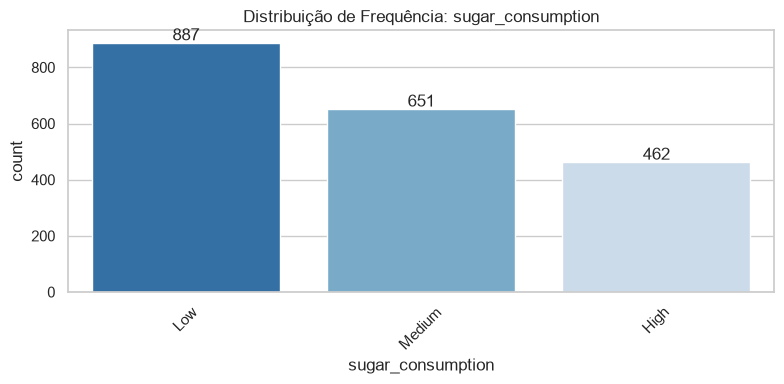

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


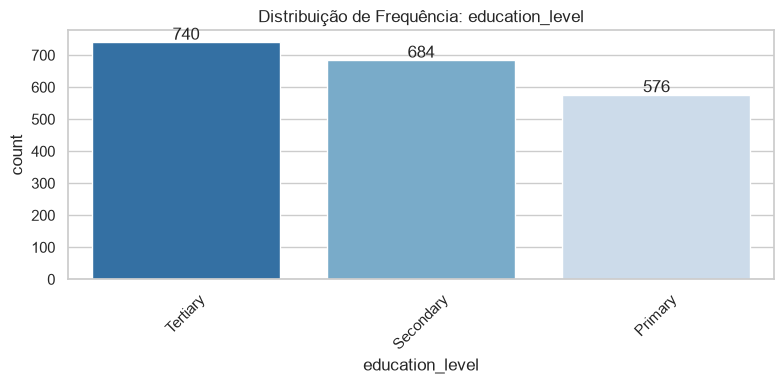

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


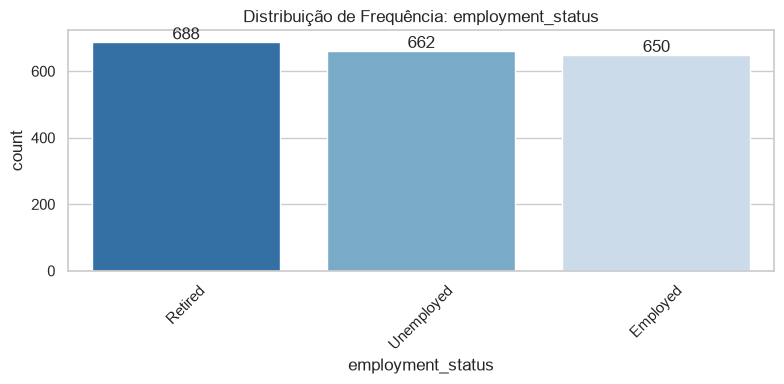

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\2104542680.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')


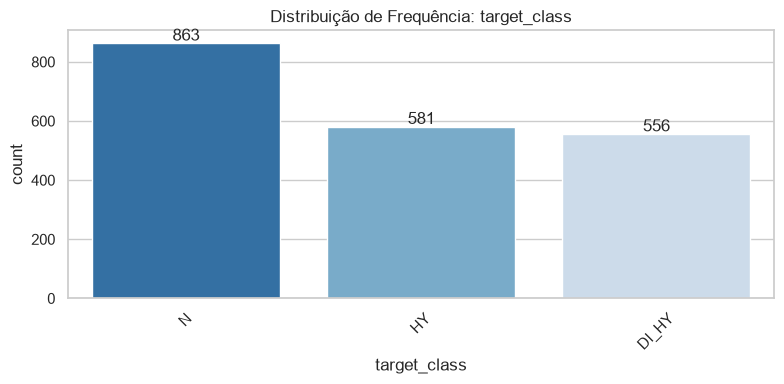

In [4]:
# Separação das colunas por tipo
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=['O']).columns

# 1. Análise Univariada - Variáveis Numéricas (Histogramas)
print("--- A gerar histogramas para variáveis numéricas ---")
df[num_cols].hist(bins=20, figsize=(16, 14), color='steelblue', edgecolor='black', grid=False)
plt.suptitle('Distribuição das Variáveis Numéricas', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# 2. Análise Univariada - Variáveis Categóricas (Gráficos de Barras e Frequências)
print("--- A gerar gráficos para variáveis categóricas ---")
for col in cat_cols:
    plt.figure(figsize=(8, 4))
    ax = sns.countplot(data=df, x=col, order=df[col].value_counts().index, palette='Blues_r')
    plt.title(f'Distribuição de Frequência: {col}')
    plt.xticks(rotation=45)
    
    # Adicionar contagens em cima das barras para facilitar a leitura no relatório
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points')
        
    plt.tight_layout()
    plt.show()

--- Correlação com 'target_regression' ---
target_regression     1.000000
crp_level             0.035336
ldl                   0.033595
plasma_value          0.028460
age                   0.028338
age_normalized        0.028338
blood_pressure        0.024940
alcohol_intake        0.018099
systolic_index        0.007601
systolic_bp           0.007601
hdl                   0.002775
ldl_alternative       0.002434
bmi                   0.000205
heart_rate           -0.003104
cholesterol          -0.009216
HbA1c_level          -0.012542
triglycerides        -0.019800
homocysteine_level   -0.020534
salt_intake          -0.020784
diastolic_bp         -0.040998
sleep_hours          -0.049979
calcium_baseline           NaN
Name: target_regression, dtype: float64


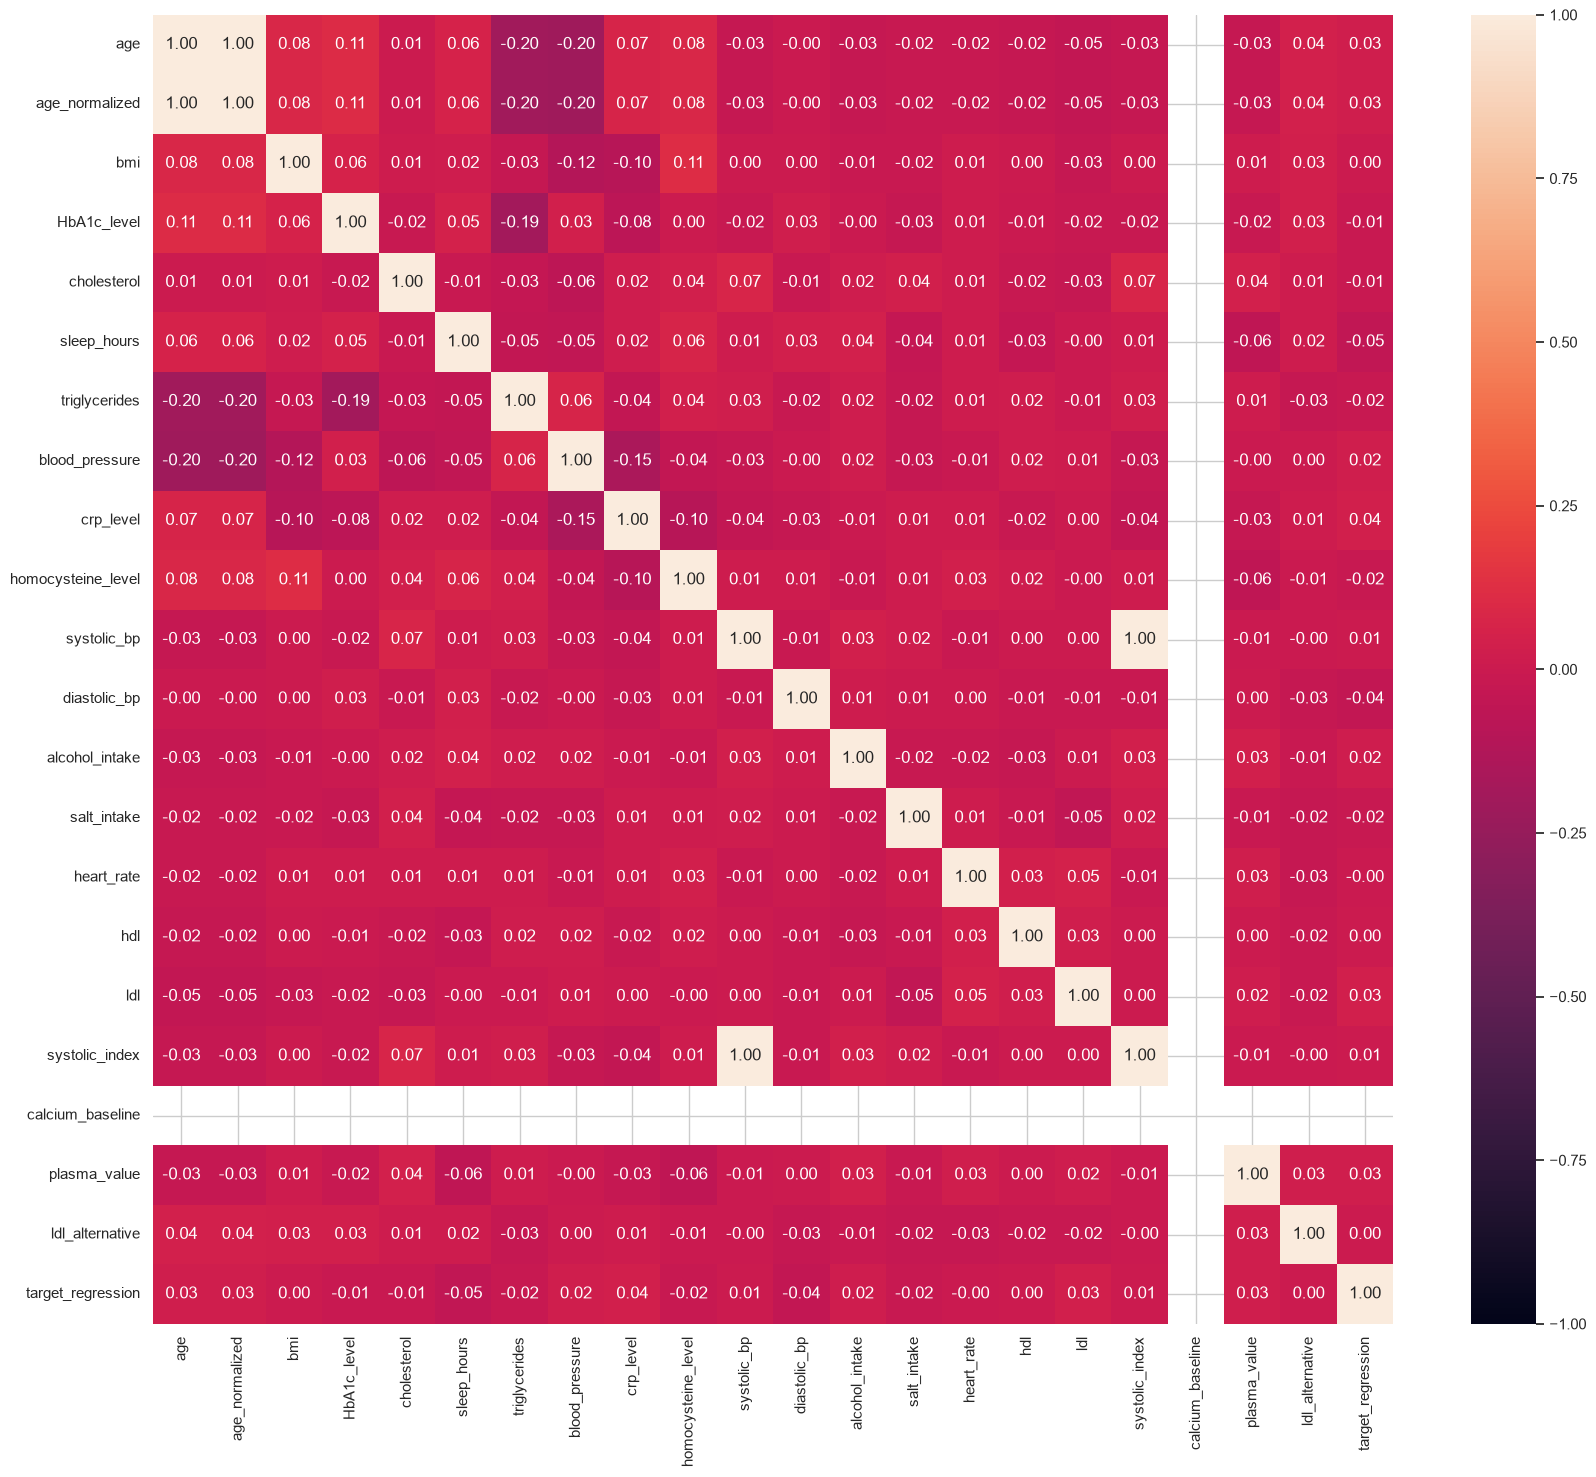


--- Variância das Variáveis Numéricas (Deteção de Constantes) ---
calcium_baseline    0.0
dtype: float64

--- Contagem de Valores Únicos (Variáveis Categóricas) ---
[age_level] -> 4 valores únicos: <StringArray>
['Mature', 'Middle', 'Young', 'Senior']
Length: 4, dtype: str
[gender] -> 2 valores únicos: <StringArray>
['Male', 'Female']
Length: 2, dtype: str
[bmi_level] -> 4 valores únicos: <StringArray>
['Obese', 'Overweight', 'Normal', 'Underweight']
Length: 4, dtype: str
[smoking] -> 3 valores únicos: <StringArray>
['Former', 'Never', 'Current']
Length: 3, dtype: str
[physical_activity] -> 3 valores únicos: <StringArray>
['High', 'Moderate', 'Low']
Length: 3, dtype: str
[family_history] -> 2 valores únicos: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
[stress_level] -> 3 valores únicos: <StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str
[low_hdl_cholesterol] -> 2 valores únicos: <StringArray>
['No', 'Yes']
Length: 2, dtype: str
[high_ldl_cholesterol] -> 2 valores únic

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\1268762818.py:22: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['O']).columns


In [5]:
# 3. Análise Bivariada e Identificação de Características

# Correlação linear com o alvo de regressão (target_regression)
print("--- Correlação com 'target_regression' ---")
num_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[num_cols].corr()
if 'target_regression' in corr_matrix.columns:
    print(corr_matrix['target_regression'].sort_values(ascending=False))

# Heatmap da Matriz de Correlação Geral
plt.figure(figsize=(20,17))
sns.heatmap(corr_matrix, vmin=-1, vmax=1, annot=True, fmt='.2f') 
plt.show()

# Deteção de Variáveis Constantes (Variância igual a 0 ou muito próxima de 0)
print("\n--- Variância das Variáveis Numéricas (Deteção de Constantes) ---")
variances = df[num_cols].var()
print(variances[variances == 0])

# Deteção de Cardinalidade em Variáveis Categóricas
print("\n--- Contagem de Valores Únicos (Variáveis Categóricas) ---")
cat_cols = df.select_dtypes(include=['O']).columns
for col in cat_cols:
    print(f"[{col}] -> {df[col].nunique()} valores únicos: {df[col].unique()[:5]}")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_4800\562886392.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target_class', y='target_regression', palette='Set3')


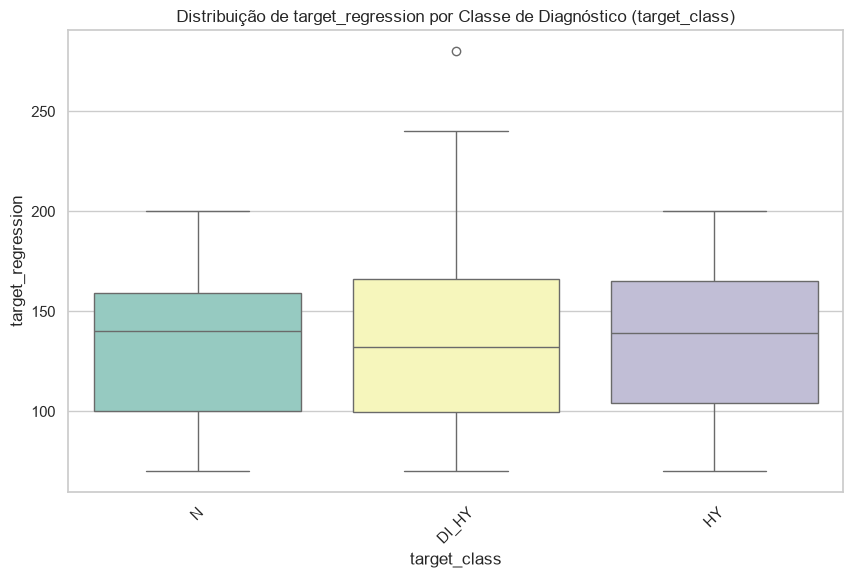

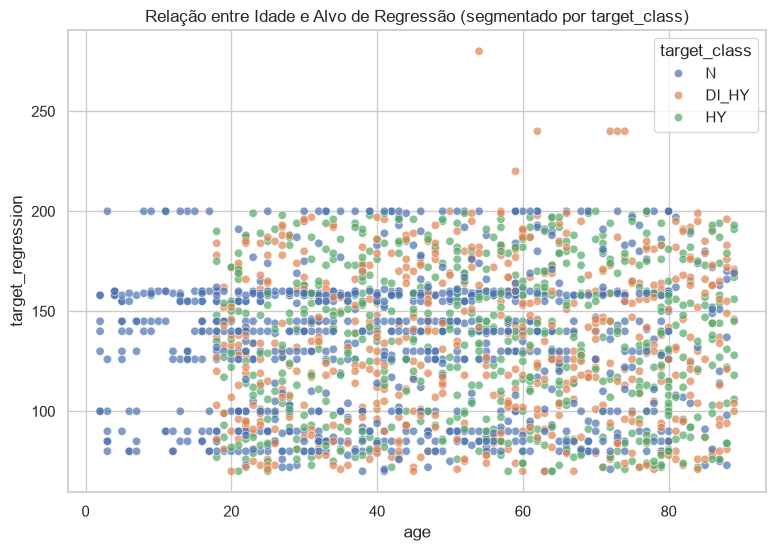

<Figure size 1000x600 with 0 Axes>

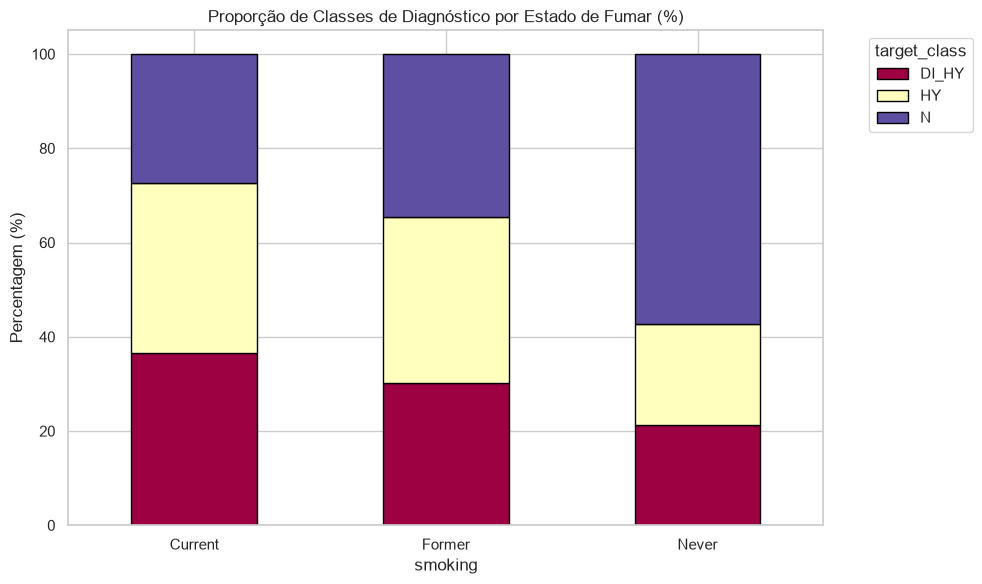

In [6]:
# 1. Categórica vs Numérica (Boxplot): Exemplo com 'target_class' e 'target_regression'
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='target_class', y='target_regression', palette='Set3')
plt.title('Distribuição de target_regression por Classe de Diagnóstico (target_class)')
plt.xticks(rotation=45)
plt.show()

# 2. Numérica vs Numérica (Scatter Plot com distinção de classes): Exemplo com 'age' e 'target_regression'
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='age', y='target_regression', hue='target_class', alpha=0.7, palette='deep')
plt.title('Relação entre Idade e Alvo de Regressão (segmentado por target_class)')
plt.show()

# 3. Categórica vs Categórica (Gráfico de Barras Empilhadas): Exemplo com 'smoking' e 'target_class'
# Calcula as percentagens por categoria
cross_tab = pd.crosstab(df['smoking'], df['target_class'], normalize='index') * 100

plt.figure(figsize=(10, 6))
cross_tab.plot(kind='bar', stacked=True, colormap='Spectral', edgecolor='black')
plt.title('Proporção de Classes de Diagnóstico por Estado de Fumar (%)')
plt.ylabel('Percentagem (%)')
plt.xlabel('smoking')
plt.xticks(rotation=0)
plt.legend(title='target_class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [7]:
# 1. Preparação dos dados (remover colunas não numéricas, valores nulos e redundâncias se necessário)
# Selecionamos apenas colunas numéricas para simplificar
df_reg = df.select_dtypes(include=[np.number]).dropna()

# Definir X (features) e y (alvo)
# Vamos excluir o próprio target_regression e variáveis redundantes detetadas (ex: 'age_normalized', 'systolic_index')
X = df_reg.drop(columns=['target_regression', 'age_normalized', 'systolic_index'], errors='ignore')
y = df_reg['target_regression']

# Divisão Holdout (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- A) REGRESSÃO LINEAR SIMPLES ---
print("=== Regressão Linear Simples (Testar melhor variável isolada) ===")
best_r2 = -float('inf')
best_feature = None
best_simples_model = None

for col in X.columns:
    X_train_single = X_train[[col]]
    X_test_single = X_test[[col]]
    
    model = LinearRegression()
    model.fit(X_train_single, y_train)
    y_pred = model.predict(X_test_single)
    
    r2 = r2_score(y_test, y_pred)
    if r2 > best_r2:
        best_r2 = r2
        best_feature = col
        best_simples_model = model

print(f"Melhor caraterística isolada: '{best_feature}' com R² = {best_r2:.4f}")

# Avaliação detalhada do melhor modelo simples
X_train_best = X_train[[best_feature]]
X_test_best = X_test[[best_feature]]
final_simples = LinearRegression().fit(X_train_best, y_train)
y_pred_simples = final_simples.predict(X_test_best)

mae_simples = mean_absolute_error(y_test, y_pred_simples)
rmse_simples = np.sqrt(mean_squared_error(y_test, y_pred_simples))
r2_simples = r2_score(y_test, y_pred_simples)

print(f"Métricas Regressão Simples -> R²: {r2_simples:.4f} | MAE: {mae_simples:.4f} | RMSE: {rmse_simples:.4f}")


# --- B) REGRESSÃO LINEAR MÚLTIPLA ---
print("\n=== Regressão Linear Múltipla (Todas as caraterísticas) ===")
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)
y_pred_multi = multi_model.predict(X_test)

mae_multi = mean_absolute_error(y_test, y_pred_multi)
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multi))
r2_multi = r2_score(y_test, y_pred_multi)

print(f"Métricas Regressão Múltipla -> R²: {r2_multi:.4f} | MAE: {mae_multi:.4f} | RMSE: {rmse_multi:.4f}")

=== Regressão Linear Simples (Testar melhor variável isolada) ===
Melhor caraterística isolada: 'crp_level' com R² = 0.0029
Métricas Regressão Simples -> R²: 0.0029 | MAE: 31.5653 | RMSE: 37.2399

=== Regressão Linear Múltipla (Todas as caraterísticas) ===
Métricas Regressão Múltipla -> R²: -0.0147 | MAE: 31.8375 | RMSE: 37.5664


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

# 1. Preparar os dados para classificação
X_class = df.select_dtypes(include=[np.number]).drop(columns=['target_regression', 'age_normalized', 'systolic_index'], errors='ignore').dropna()
y_class = df.loc[X_class.index, 'target_class']

# Instanciar os modelos
log_reg = LogisticRegression(max_iter=1000, random_state=42)
lda = LinearDiscriminantAnalysis()

resultados = []

# --- 1. Holdout (80/20) ---
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42, stratify=y_class)
log_reg.fit(X_train_c, y_train_c)
lda.fit(X_train_c, y_train_c)

resultados.append({"Método": "Holdout (80/20)", "Regressão Logística": accuracy_score(y_test_c, log_reg.predict(X_test_c)), "LDA": accuracy_score(y_test_c, lda.predict(X_test_c))})

# --- 2. Cross-Validation (k=5 e k=10) ---
for k in [5, 10]:
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    scores_lr = cross_val_score(log_reg, X_class, y_class, cv=cv, scoring='accuracy')
    scores_lda = cross_val_score(lda, X_class, y_class, cv=cv, scoring='accuracy')
    resultados.append({"Método": f"Cross-Val (k={k})", "Regressão Logística": f"{scores_lr.mean():.4f} (±{scores_lr.std():.4f})", "LDA": f"{scores_lda.mean():.4f} (±{scores_lda.std():.4f})"})

# --- 3. Bootstrap (Reduzido para 20 iterações para ser rápido e limpo) ---
boot_lr, boot_lda = [], []
rng = np.random.default_rng(42)
for _ in range(20):
    indices = rng.choice(len(X_class), size=len(X_class), replace=True)
    log_reg.fit(X_class.iloc[indices], y_class.iloc[indices])
    lda.fit(X_class.iloc[indices], y_class.iloc[indices])
    boot_lr.append(accuracy_score(y_test_c, log_reg.predict(X_test_c)))
    boot_lda.append(accuracy_score(y_test_c, lda.predict(X_test_c)))

resultados.append({"Método": "Bootstrap (20 iter.)", "Regressão Logística": f"{np.mean(boot_lr):.4f} (±{np.std(boot_lr):.4f})", "LDA": f"{np.mean(boot_lda):.4f} (±{np.std(boot_lda):.4f})"})

# Exibir tabela limpa e organizada
df_res = pd.DataFrame(resultados)
display(df_res)

c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessi

,Método,Regressão Logística,LDA
0,Holdout (80/20),0.7375,0.715
1,Cross-Val (k=5),0.7340 (±0.0141),0.7250 (±0.0119)
2,Cross-Val (k=10),0.7305 (±0.0277),0.7260 (±0.0241)
3,Bootstrap (20 iter.),0.7429 (±0.0071),0.7289 (±0.0095)


In [10]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Normalizar os dados é obrigatório para regularização (Ridge e Lasso)
# Vamos usar LogisticRegressionCV para testar automaticamente os melhores hiperparâmetros (C)

# 1. Ridge (Penalty L2) com todas as caraterísticas
ridge_model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10, penalty='l2', solver='lbfgs', cv=5, max_iter=1000, random_state=42))
ridge_model.fit(X_class, y_class)
print(f"Acurácia com Ridge (L2) - Todas as features: {ridge_model.score(X_class, y_class):.4f}")

# 2. Lasso (Penalty L1) com todas as caraterísticas (requer solver como 'saga')
lasso_model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=10, penalty='l1', solver='saga', cv=5, max_iter=1000, random_state=42))
lasso_model.fit(X_class, y_class)
print(f"Acurácia com Lasso (L1) - Todas as features: {lasso_model.score(X_class, y_class):.4f}")

# Extrair os coeficientes do modelo Lasso para ver quais caraterísticas foram eliminadas (coeficiente = 0)
clf_lasso = lasso_model.named_steps['logisticregressioncv']
coefs = pd.DataFrame(clf_lasso.coef_[0], index=X_class.columns, columns=['Coeficiente'])
coefs['Abs_Coef'] = coefs['Coeficiente'].abs()

print("\n--- Top caraterísticas retidas pelo Lasso (Coeficiente != 0) ---")
display(coefs[coefs['Abs_Coef'] > 0.001].sort_values(by='Abs_Coef', ascending=False))

print(f"\nNúmero de caraterísticas eliminadas pelo Lasso: {sum(coefs['Abs_Coef'] <= 0.001)} em {len(X_class.columns)}")

c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of

Acurácia com Ridge (L2) - Todas as features: 0.7420


c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2102: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratios' and 'Cs' instead. Use l1_ratios=(0,) instead of penalty='l2', l1_ratios=(1,) instead of penalty='l1', l1_ratios set to floats between 0 and 1 instead of penalty='elasticnet', and Cs=(np.inf,) instead of penalty=None.
  warnings.warn(
c:\Users\ASUS\Downloads\env\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:2116: FutureWarning: The default value of

Acurácia com Lasso (L1) - Todas as features: 0.7390

--- Top caraterísticas retidas pelo Lasso (Coeficiente != 0) ---


,Coeficiente,Abs_Coef
HbA1c_level,6.732302,6.732302
triglycerides,-0.571122,0.571122
blood_pressure,0.415413,0.415413
age,0.336485,0.336485
crp_level,-0.262600,0.262600
heart_rate,-0.196087,0.196087
ldl,-0.180292,0.180292
homocysteine_level,-0.155526,0.155526
bmi,-0.154554,0.154554
sleep_hours,0.093372,0.093372



Número de caraterísticas eliminadas pelo Lasso: 4 em 19


In [11]:
# Identificar as caraterísticas eliminadas pelo Lasso (onde o coeficiente é 0 ou muito próximo de 0)
features_eliminadas = coefs[coefs['Abs_Coef'] <= 0.001].index.tolist()

print("--- Caraterísticas Eliminadas pelo Lasso ---")
if features_eliminadas:
    for feat in features_eliminadas:
        print(f"- {feat}")
else:
    print("Nenhuma caraterística foi totalmente eliminada (coeficientes diferentes de zero para todas).")

--- Caraterísticas Eliminadas pelo Lasso ---
- systolic_bp
- hdl
- calcium_baseline
- ldl_alternative
